# Probability boxes for one five-dimensional event

The first three coordinates and last two coordinates are treated as independent probability blocks. For each block, randomly selected sample values define one-dimensional separators at the midpoints of adjacent selected values. The outer separators are the minimum and maximum of all samples. Empty cells and cells containing only one sample are discarded. Each retained box is shrunk to the coordinate range of its assigned samples.

For a retained box $B$, with $n_B$ of the original $N$ samples and hypervolume $V_B$, the constant density is

$$p_B = \frac{n_B}{N V_B}, \qquad \sum_B p_B V_B = \frac{N_{\mathrm{retained}}}{N}.$$

The product of the retained probabilities of the 3D and 2D blocks is the event's retained probability. Discarded sample probability is not redistributed. The chosen sample values set the separators; with uneven spacing, they do not generally coincide with the geometric centers of their final cells. The box weight is one for now.

[Run instructions](../RUNNING.md) · [Consolidated scientific report](report.md)


In [1]:
import os
import shutil
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib_box_overlap")

from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc, rcParams, font_manager
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from cycler import cycler

project_root = Path.cwd()
if project_root.name == "validation":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from bo import make_event_boxes, make_box_trials, partition_bounds

from validation.plot_style import plot_style
plt = plot_style()


Install dvipng separately for LaTeX plot text.
Install a Times font separately for the requested plot font.


## Choose the event and the number of selected samples

`n_centers_3d` and `n_centers_2d` control the number of intervals per coordinate. The maximum possible box counts are their third and second powers, respectively; empty and one-sample cells are removed. Change `idx` to inspect another event. A warning appears if more than 0.1% of the event probability is discarded.
`ntrial=(5,10)` chooses five 3D and ten 2D random grids and keeps the smallest summed hypervolume in each block. `subdivisions=(0,3)` controls the index: zero levels in 3D, three levels in 2D.


In [2]:
idx = 1
n_centers_3d = 4
n_centers_2d = 8
seed = 91 + idx  # Same event seed as the measured jobs.
ntrial = (5, 10)
subdivisions = (0, 3)
save_plots = False

samples = np.load(project_root / "validation" / "ARAK_samples" / f"event_{idx}.npy", mmap_mode="r")
event = make_event_boxes(samples, n_centers=(n_centers_3d, n_centers_2d),
                         rng=np.random.default_rng(seed), ntrial=ntrial)
boxes_3d, boxes_2d = event

# Repeat the trial sequence to recover the winning selected samples for plots.
rng = np.random.default_rng(seed)
trials_3d = make_box_trials(samples[:, :3], n_centers_3d, ntrial[0], rng)
trials_2d = make_box_trials(samples[:, 3:], n_centers_2d, ntrial[1], rng)
selected_3d, selected_2d = trials_3d.centers, trials_2d.centers
np.testing.assert_array_equal(boxes_3d.rows(), trials_3d.boxes.rows())
np.testing.assert_array_equal(boxes_2d.rows(), trials_2d.boxes.rows())

for name, boxes in (("3D", boxes_3d), ("2D", boxes_2d)):
    print(f"{name}: {boxes.n_boxes} retained boxes, retained probability = "
          f"{boxes.retained_probability:.6f}")
print(f"Event retained probability = {event.retained_probability:.6f}")

3D: 58 retained boxes, retained probability = 0.999900
2D: 20 retained boxes, retained probability = 1.000000
Event retained probability = 0.999900


## Samples and box boundaries

The lower triangle shows joint sample scatter. Navy outlines are projections of the final sample-bounded boxes for pairs of coordinates in the same block. Coral dots mark the selected samples that set those boundaries; a dot can lie outside the retained boxes when its cell contained only one sample. Cross-block panels show the original joint samples only. A projection of a 3D box can overlap another projection even though the full 3D boxes have disjoint interiors.

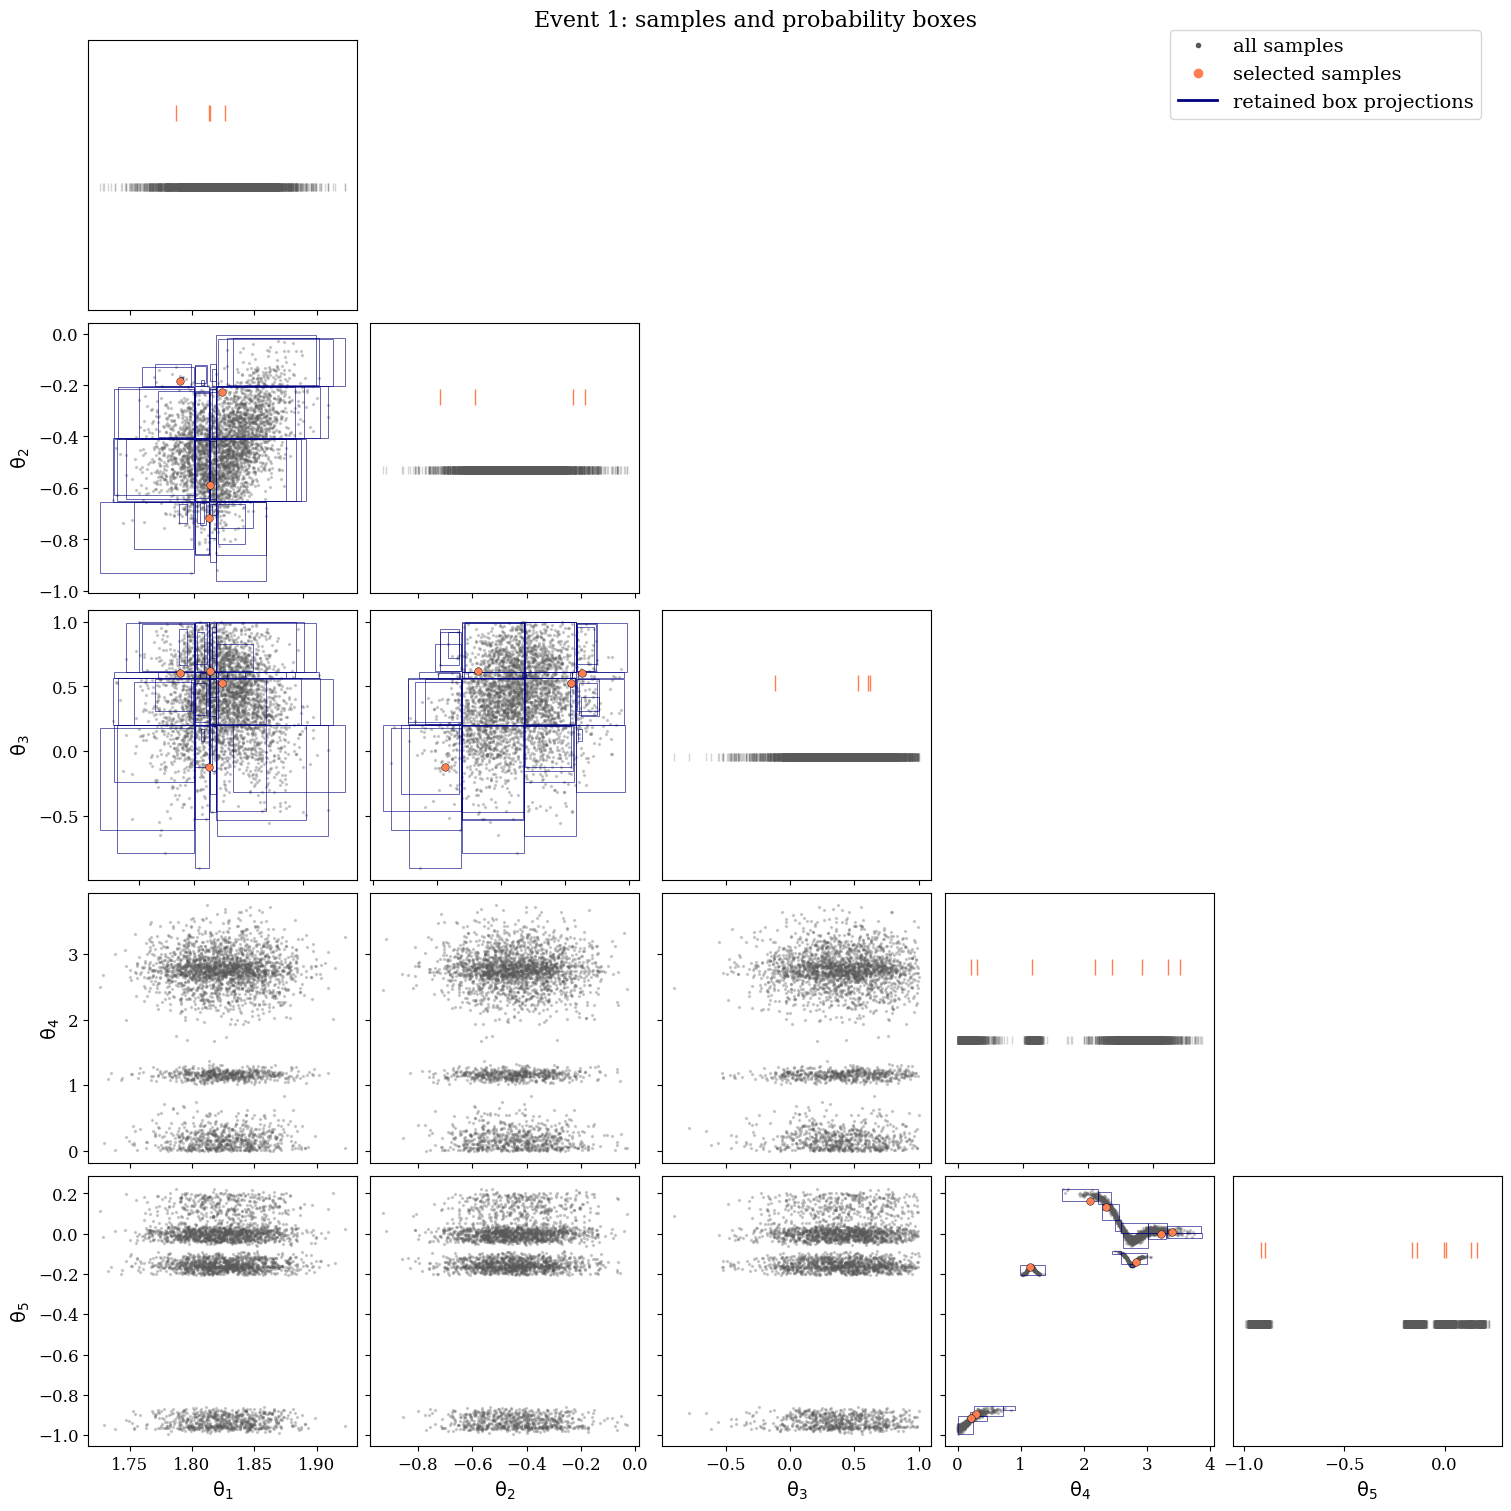

In [3]:
labels = [r'$\theta_1$', r'$\theta_2$', r'$\theta_3$',
          r'$\theta_4$', r'$\theta_5$']
shown = samples[::max(1, len(samples) // 3000)]
fig, axes = plt.subplots(5, 5, figsize=(15, 15), constrained_layout=True)
for row in range(5):
    for col in range(5):
        ax = axes[row, col]
        if row < col:
            ax.set_visible(False)
            continue
        if row == col:
            ax.plot(shown[:, col], np.zeros(len(shown)), '|', color='0.35', alpha=.25)
            chosen = selected_3d[:, col] if col < 3 else selected_2d[:, col - 3]
            ax.plot(chosen, np.full(len(chosen), .06), '|', color='coral', markersize=11)
            ax.set_ylim(-.1, .12)
            ax.set_yticks([])
        else:
            ax.scatter(shown[:, col], shown[:, row], s=2, color='0.35', alpha=.25,
                       rasterized=True)
            if row < 3:
                boxes, chosen, x, y = boxes_3d, selected_3d, col, row
            elif col >= 3:
                boxes, chosen, x, y = boxes_2d, selected_2d, col - 3, row - 3
            else:
                boxes = None
            if boxes is not None:
                for lower, upper in zip(boxes.lower, boxes.upper):
                    ax.add_patch(Rectangle((lower[x], lower[y]),
                                           upper[x] - lower[x], upper[y] - lower[y],
                                           fill=False, edgecolor='navy', linewidth=.7,
                                           alpha=.6))
                ax.scatter(chosen[:, x], chosen[:, y], s=30, color='coral',
                           edgecolor='black', linewidth=.3, zorder=5)
        if row == 4:
            ax.set_xlabel(labels[col])
        else:
            ax.set_xticklabels([])
        if col == 0 and row > 0:
            ax.set_ylabel(labels[row])
        elif col > 0 and row > col:
            ax.set_yticklabels([])

fig.legend(handles=[Line2D([], [], marker='.', linestyle='', color='0.35', label='all samples'),
                    Line2D([], [], marker='o', linestyle='', color='coral', label='selected samples'),
                    Line2D([], [], color='navy', label='retained box projections')],
           loc='upper right', bbox_to_anchor=(.99, .99), frameon=True)
fig.suptitle(f'Event {idx}: samples and probability boxes', fontsize=16)
if save_plots:
    fig.savefig(project_root / 'validation' / f'event_{idx}_samples_boxes.jpg', dpi=200)
plt.show()

## Density in the retained boxes

Color is the recomputed constant density in each full-dimensional box after shrinking. The first three panels project 3D boxes onto coordinate pairs, so several differently colored boxes can appear in the same projected area. The final panel shows the actual nonoverlapping 2D boxes. The color scales are separate because 3D and 2D densities have different units.

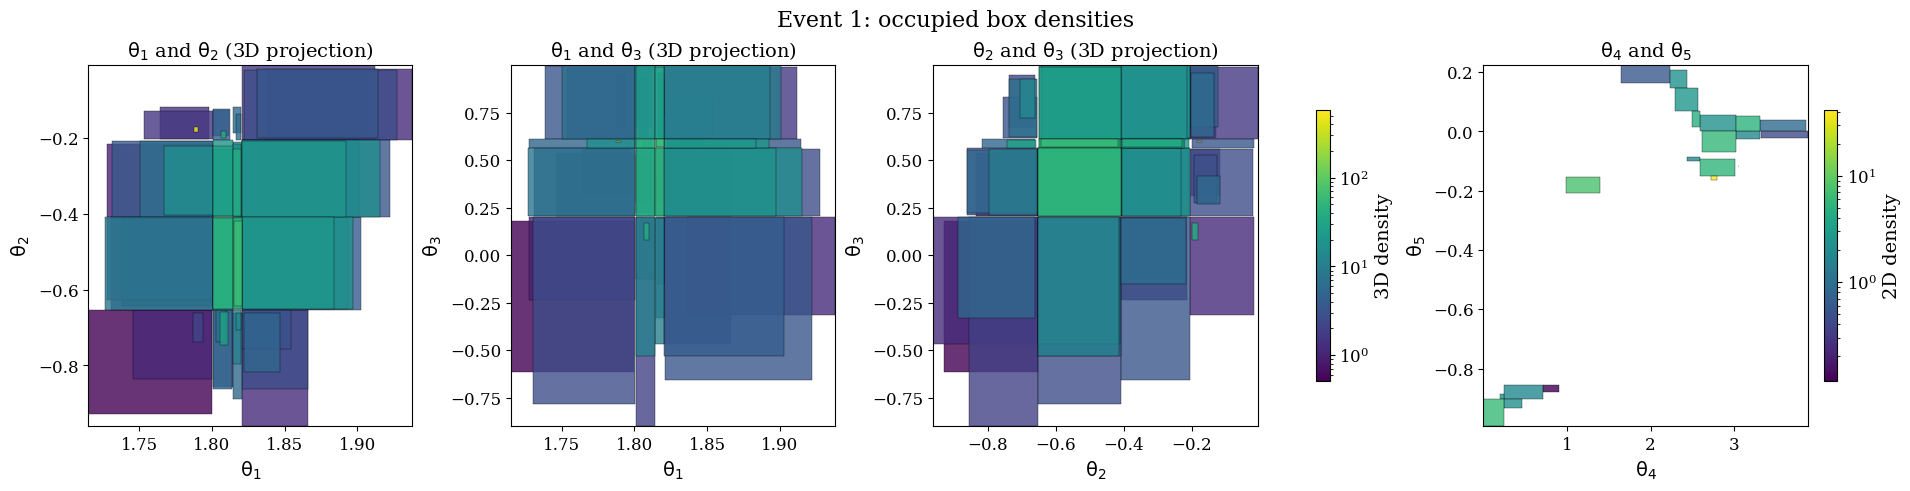

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.8), constrained_layout=True)
norm_3d = LogNorm(vmin=boxes_3d.density.min(), vmax=boxes_3d.density.max())
norm_2d = LogNorm(vmin=boxes_2d.density.min(), vmax=boxes_2d.density.max())
for ax, (x, y) in zip(axes, ((0, 1), (0, 2), (1, 2), (3, 4))):
    if x < 3:
        boxes, norm, local_x, local_y = boxes_3d, norm_3d, x, y
    else:
        boxes, norm, local_x, local_y = boxes_2d, norm_2d, x - 3, y - 3
    # Draw high-density boxes last where their 3D projections overlap.
    for k in np.argsort(boxes.density):
        lower, upper = boxes.lower[k], boxes.upper[k]
        ax.add_patch(Rectangle((lower[local_x], lower[local_y]),
                               upper[local_x] - lower[local_x],
                               upper[local_y] - lower[local_y],
                               facecolor=plt.cm.viridis(norm(boxes.density[k])),
                               edgecolor='black', linewidth=.3, alpha=.8))
    ax.set_xlim(samples[:, x].min(), samples[:, x].max())
    ax.set_ylim(samples[:, y].min(), samples[:, y].max())
    ax.set_xlabel(labels[x])
    ax.set_ylabel(labels[y])
    suffix = ' (3D projection)' if x < 3 else ''
    ax.set_title(f'{labels[x]} and {labels[y]}{suffix}')

fig.colorbar(ScalarMappable(norm=norm_3d, cmap='viridis'), ax=list(axes[:3]),
             shrink=.75, label=r'3D density')
fig.colorbar(ScalarMappable(norm=norm_2d, cmap='viridis'), ax=axes[3],
             shrink=.75, label=r'2D density')
fig.suptitle(f'Event {idx}: occupied box densities', fontsize=16)
if save_plots:
    fig.savefig(project_root / 'validation' / f'event_{idx}_densities.jpg', dpi=200)
plt.show()

## Choosing the smallest-volume realisation

Each trial uses fresh random center samples. Its objective is
$$H_t=\sum_{B\in t}\prod_k(u_{Bk}-l_{Bk}),\qquad t_* = \operatorname{argmin}_t H_t.$$
Singleton cells are discarded and retained boxes are shrunk before measuring $H_t$. The selected samples plotted above belong to the winning trials. This geometric objective can also favour more discarded singleton probability, so the retained-probability warning remains active.


Install dvipng separately for LaTeX plot text.
Install a Times font separately for the requested plot font.


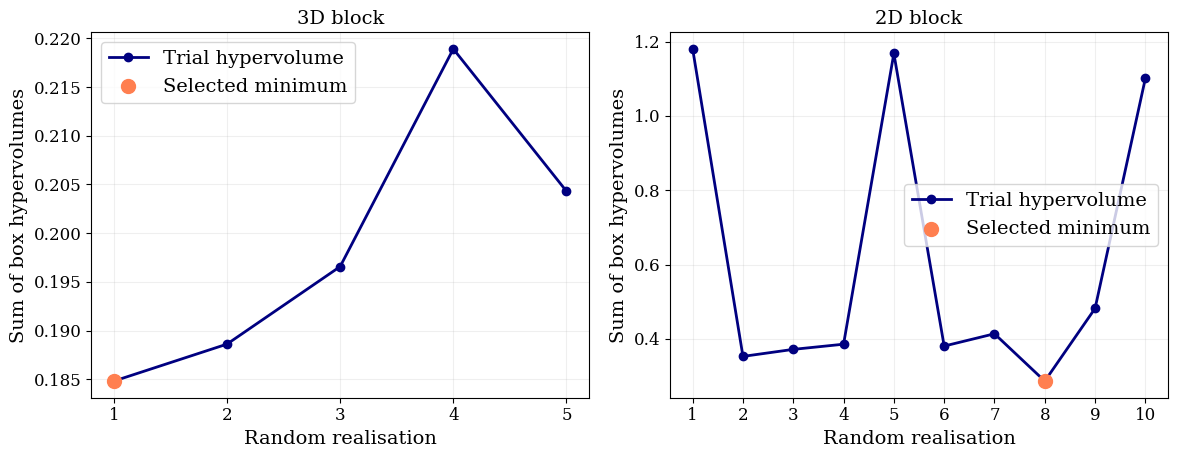

3D: selected trial 1; volume / first trial = 1.0000
2D: selected trial 8; volume / first trial = 0.2429


In [5]:
sys.path.insert(0, str(project_root / "validation"))
from plot_box_choices import plot_trials, plot_partition_levels

choice_folder = project_root / "validation" / "notebook_results"
choice_folder.mkdir(exist_ok=True)
fig = plot_trials((trials_3d, trials_2d), choice_folder / "box_trials.jpg")
plt.show()
for trial in (trials_3d, trials_2d):
    print(f"{trial.boxes.dimension}D: selected trial {trial.selected_trial+1}; "
          f"volume / first trial = {trial.hypervolumes.min()/trial.hypervolumes[0]:.4f}")


## Three subdivision levels

For a group $G$ and a cut into $G_L,G_R$, the split minimises $V(\mathrm{bbox}(G_L))+V(\mathrm{bbox}(G_R))$. Cuts are tested along every coordinate using whole-box centers. Each level splits every group with at least two boxes, so three levels produce up to eight groups; the first block has zero levels. Bounds cover complete density boxes, even when a box crosses the center-based cut position. Bounds can therefore overlap and their summed volume need not decrease at every split.

The figure compares an ARAK event and a synthetic four-mode example. The latter makes the empty gaps between modes visible. These bounds affect rejection only; density and integral calculations use the original disjoint boxes.


Install dvipng separately for LaTeX plot text.
Install a Times font separately for the requested plot font.


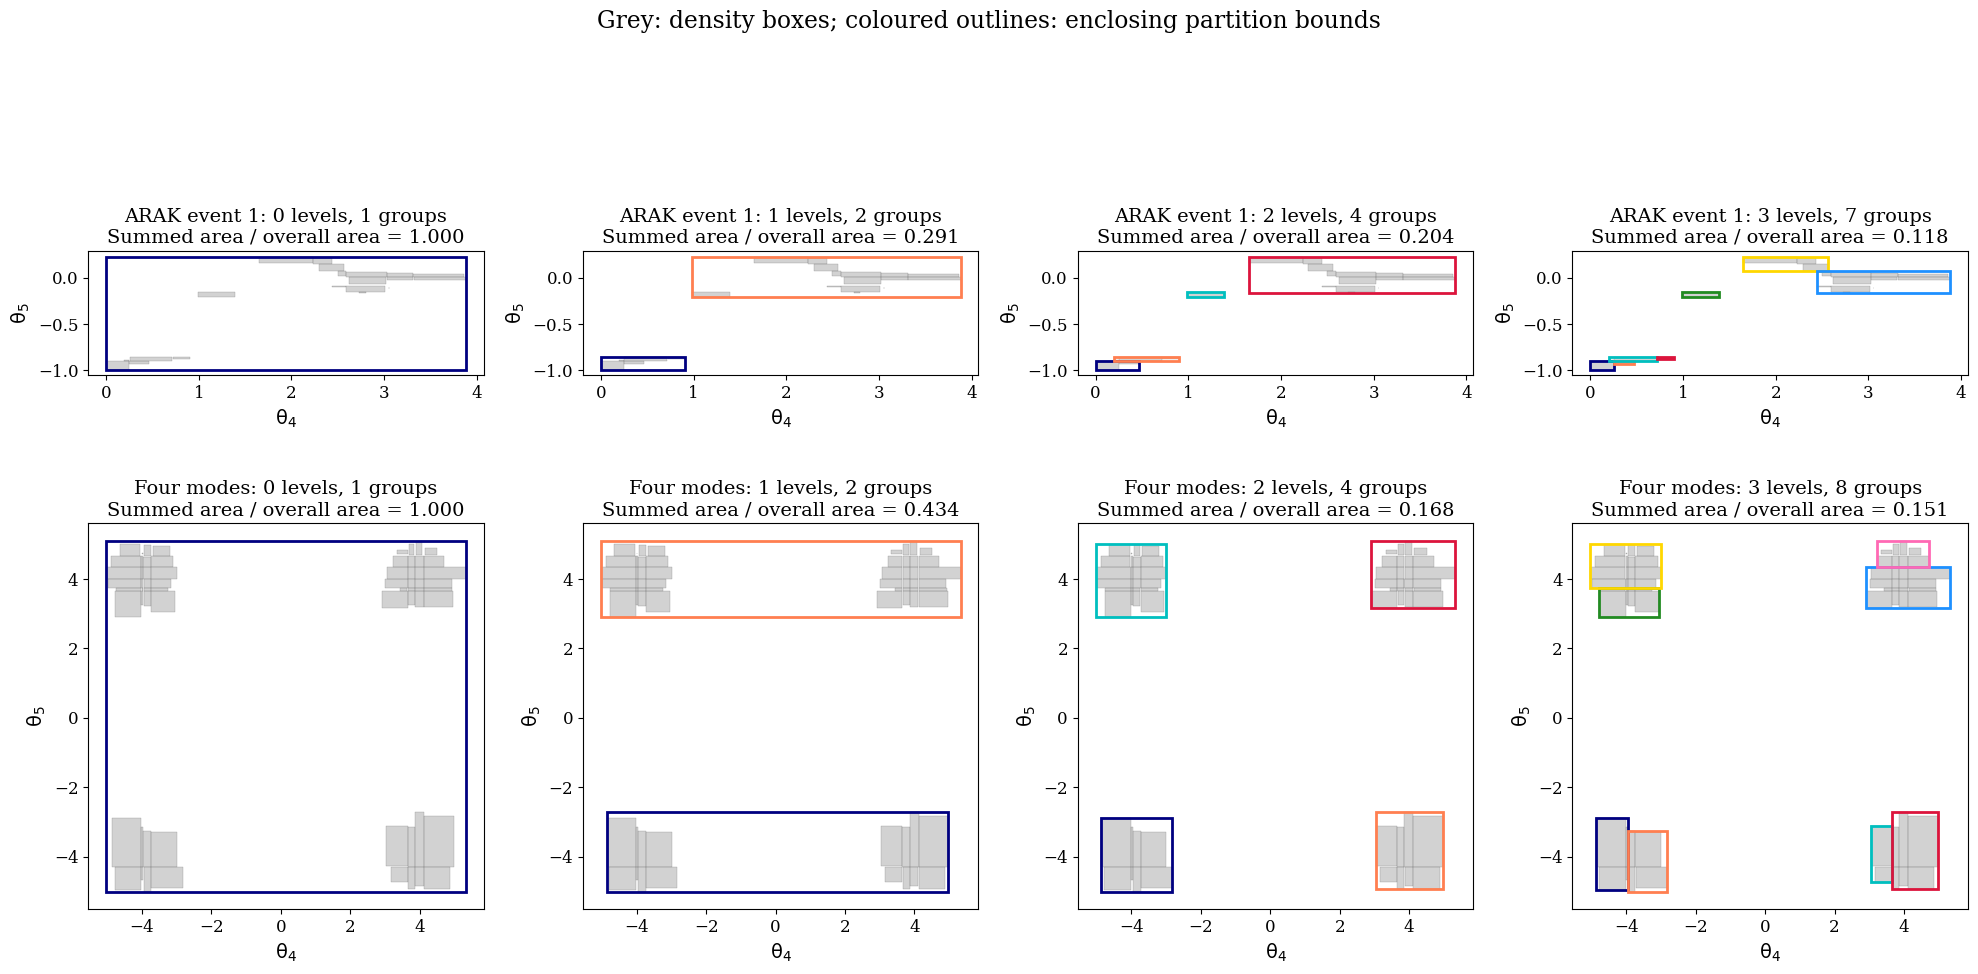

In [6]:
rng_modes = np.random.default_rng(162)
mode_centers = np.array([[-4., -4.], [-4., 4.], [4., -4.], [4., 4.]])
mode_ids = rng_modes.integers(0, 4, size=10000)
synthetic = np.column_stack((rng_modes.normal(size=(10000, 3)),
                            mode_centers[mode_ids]+rng_modes.normal(scale=.3, size=(10000, 2))))
mode_event = make_event_boxes(synthetic, rng=np.random.default_rng(172), ntrial=ntrial)
fig = plot_partition_levels((event, mode_event), (f"ARAK event {idx}", "Four modes"),
                            choice_folder / "partition_bounds.jpg")
plt.show()


## Two-event overlap

The overlap is computed by sorted C++ loops, checking the first (3D) block first.
For intersecting boxes $A,B$, let $v$ be their intersection volume and $V_A,V_B$
their full volumes. Their contribution is

$$v p_A p_B\frac{w_A/V_A+w_B/V_B}{1/V_A+1/V_B}.$$

The event result is the product of the two block sums. This assumes unit weights
or a weight that factors into one function for each independent block. A general
weight coupling the blocks cannot be represented by the stored block weights.

The sample histogram estimate uses shared 2D and 3D bin edges and unit weights.
Differences from the box result reflect the density approximation and histogram
sampling noise. The second comparison paints the box densities onto a dense
midpoint grid; it should approach the exact C++ answer as resolution increases.
Choose `idx1` and `idx2` below to compare other events.


In [7]:
sys.path.insert(0, str(project_root / "validation"))
from bo import overlap_1v1, prepare_event
from compare_overlap import compare_block

idx1, idx2 = 567, 877  # Nonzero pair from the current comparison.
samples_a = np.load(project_root / "validation" / "ARAK_samples" / f"event_{idx1}.npy", mmap_mode="r")
samples_b = np.load(project_root / "validation" / "ARAK_samples" / f"event_{idx2}.npy", mmap_mode="r")
event_a = make_event_boxes(samples_a, rng=np.random.default_rng(91 + idx1))
event_b = make_event_boxes(samples_b, rng=np.random.default_rng(91 + idx2))
prepared_a, prepared_b = prepare_event(event_a), prepare_event(event_b)
exact = overlap_1v1(prepared_a, prepared_b)
print(f"Events {idx1} and {idx2}: exact box overlap = {exact:.8g}")
print(" bins     sample histogram      box midpoint grid       grid relative error")
for bins in (24, 48, 96, 192):
    sample_estimate, grid_estimate = 1., 1.
    for columns, a, b in zip((slice(0, 3), slice(3, 5)), event_a.blocks, event_b.blocks):
        sample_value, grid_value = compare_block(samples_a[:, columns], samples_b[:, columns],
                                                 a, b, bins)
        sample_estimate *= sample_value
        grid_estimate *= grid_value
    relative_error = abs(grid_estimate / exact - 1) if exact != 0 else float("nan")
    print(f"{bins:5d}     {sample_estimate:16.8g}     {grid_estimate:16.8g}"
          f"     {relative_error:16.3%}")

Events 567 and 877: exact box overlap = 31.579238
 bins     sample histogram      box midpoint grid       grid relative error
   24            82.906839            41.087929              30.111%
   48            66.202884            37.914753              20.062%
   96             60.70671            30.444163               3.594%
  192            54.291045             31.53661               0.135%


### Where the two events intersect

The top row uses analytic box intersections; the bottom row uses the product
of the dense sample histograms. Navy and coral identify events A and B. Outlines
show boxes in the top row; contours show 10%, 50%, and 90% of each event's
marginal histogram peak in the bottom row. Blank pixels have zero overlap. The
color scale is shared between methods within each column.

For the 3D block, each panel shows
$G_{ij}(\theta_i,\theta_j)=\int P_A(\boldsymbol\theta)P_B(\boldsymbol\theta)\,d\theta_k$,
where $k$ is the omitted coordinate. Full 3D intersections are computed **before**
projection. Each panel's integral therefore equals the full 3D block overlap;
separately projecting the two PDFs and multiplying them would not do this.

Box pixels average the exact intersection contributions over their area, and
their integrals are checked against the C++ result. The second figure zooms to
the nonzero overlap support to make the narrow 2D intersection visible.
Use the `idx1`, `idx2` selected above and change `intersection_bins` to inspect
histogram resolution. Both plots use unit weights.


Install dvipng separately for LaTeX plot text.
Install a Times font separately for the requested plot font.


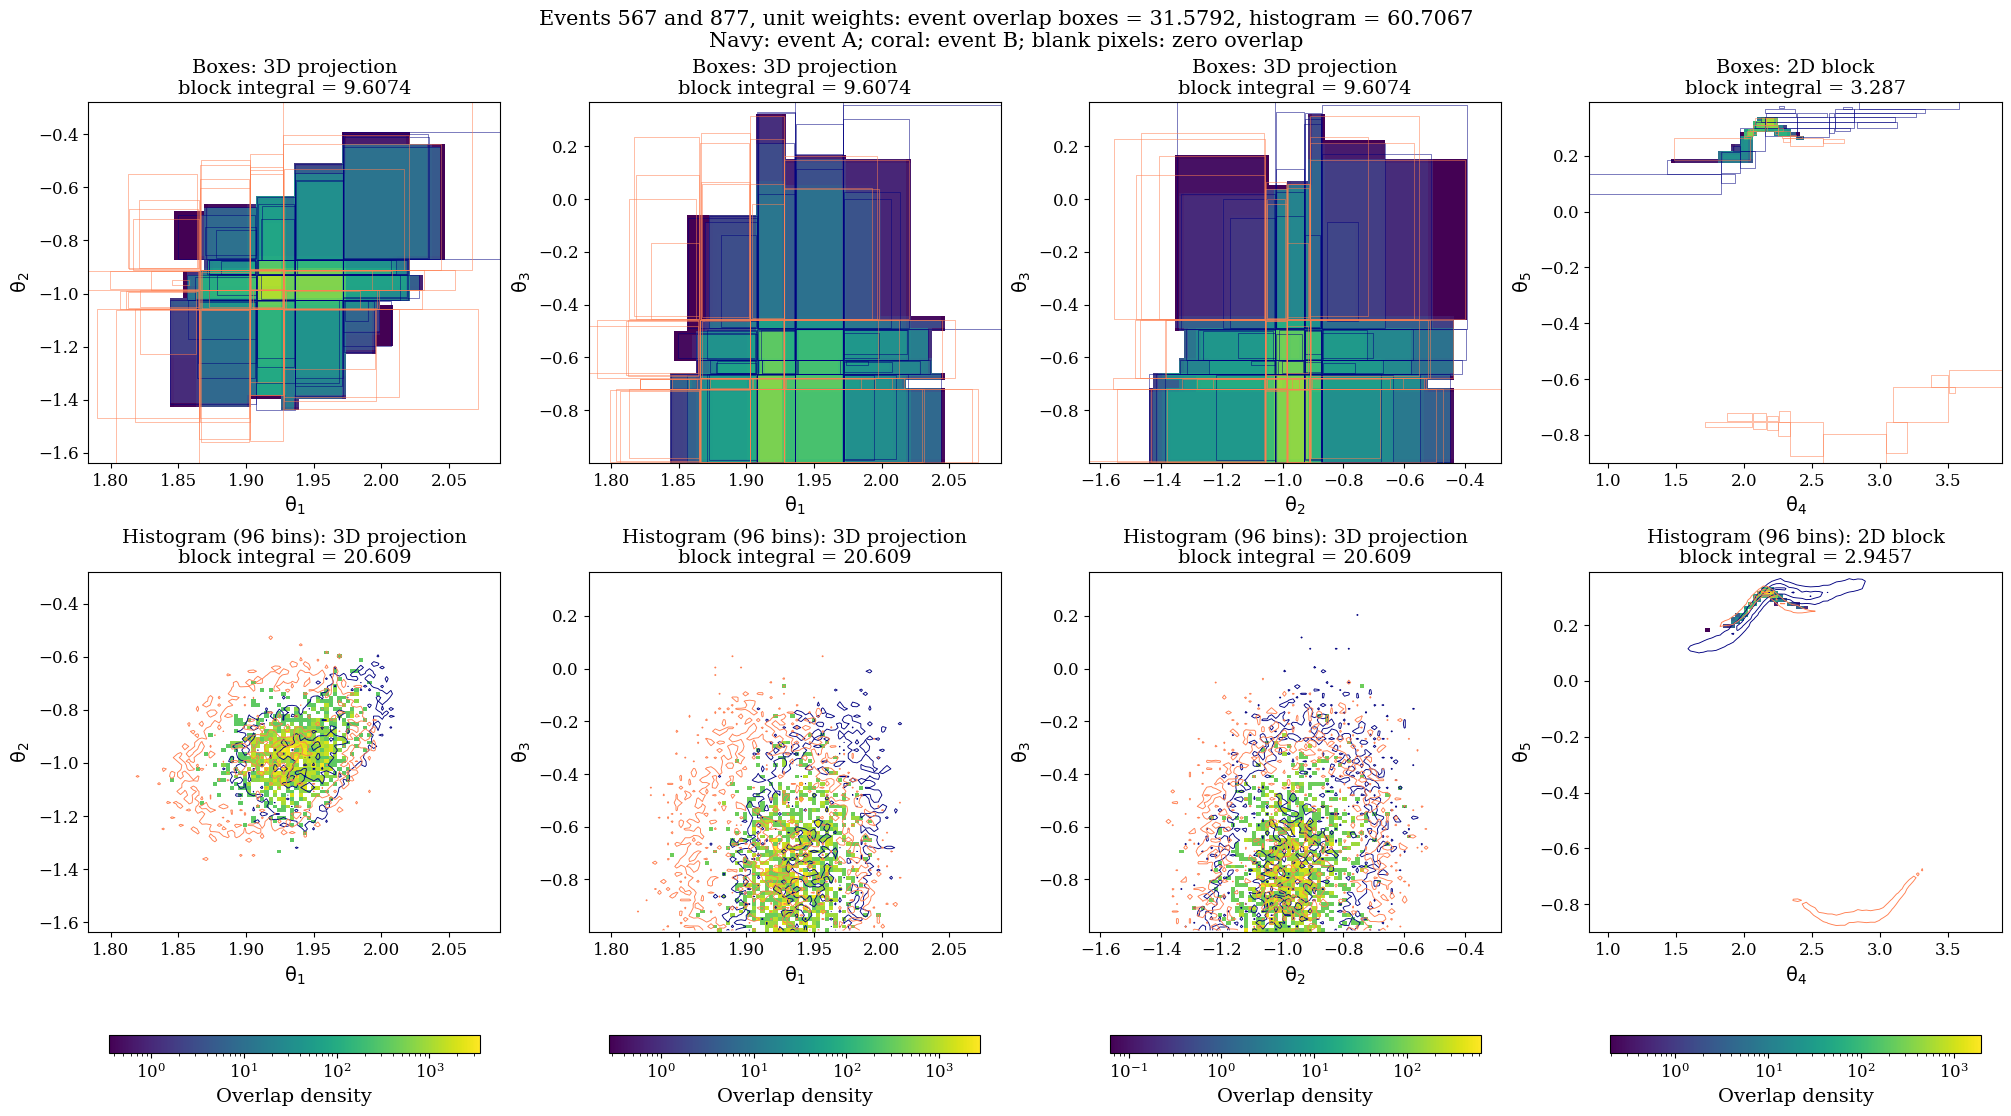

Install dvipng separately for LaTeX plot text.
Install a Times font separately for the requested plot font.


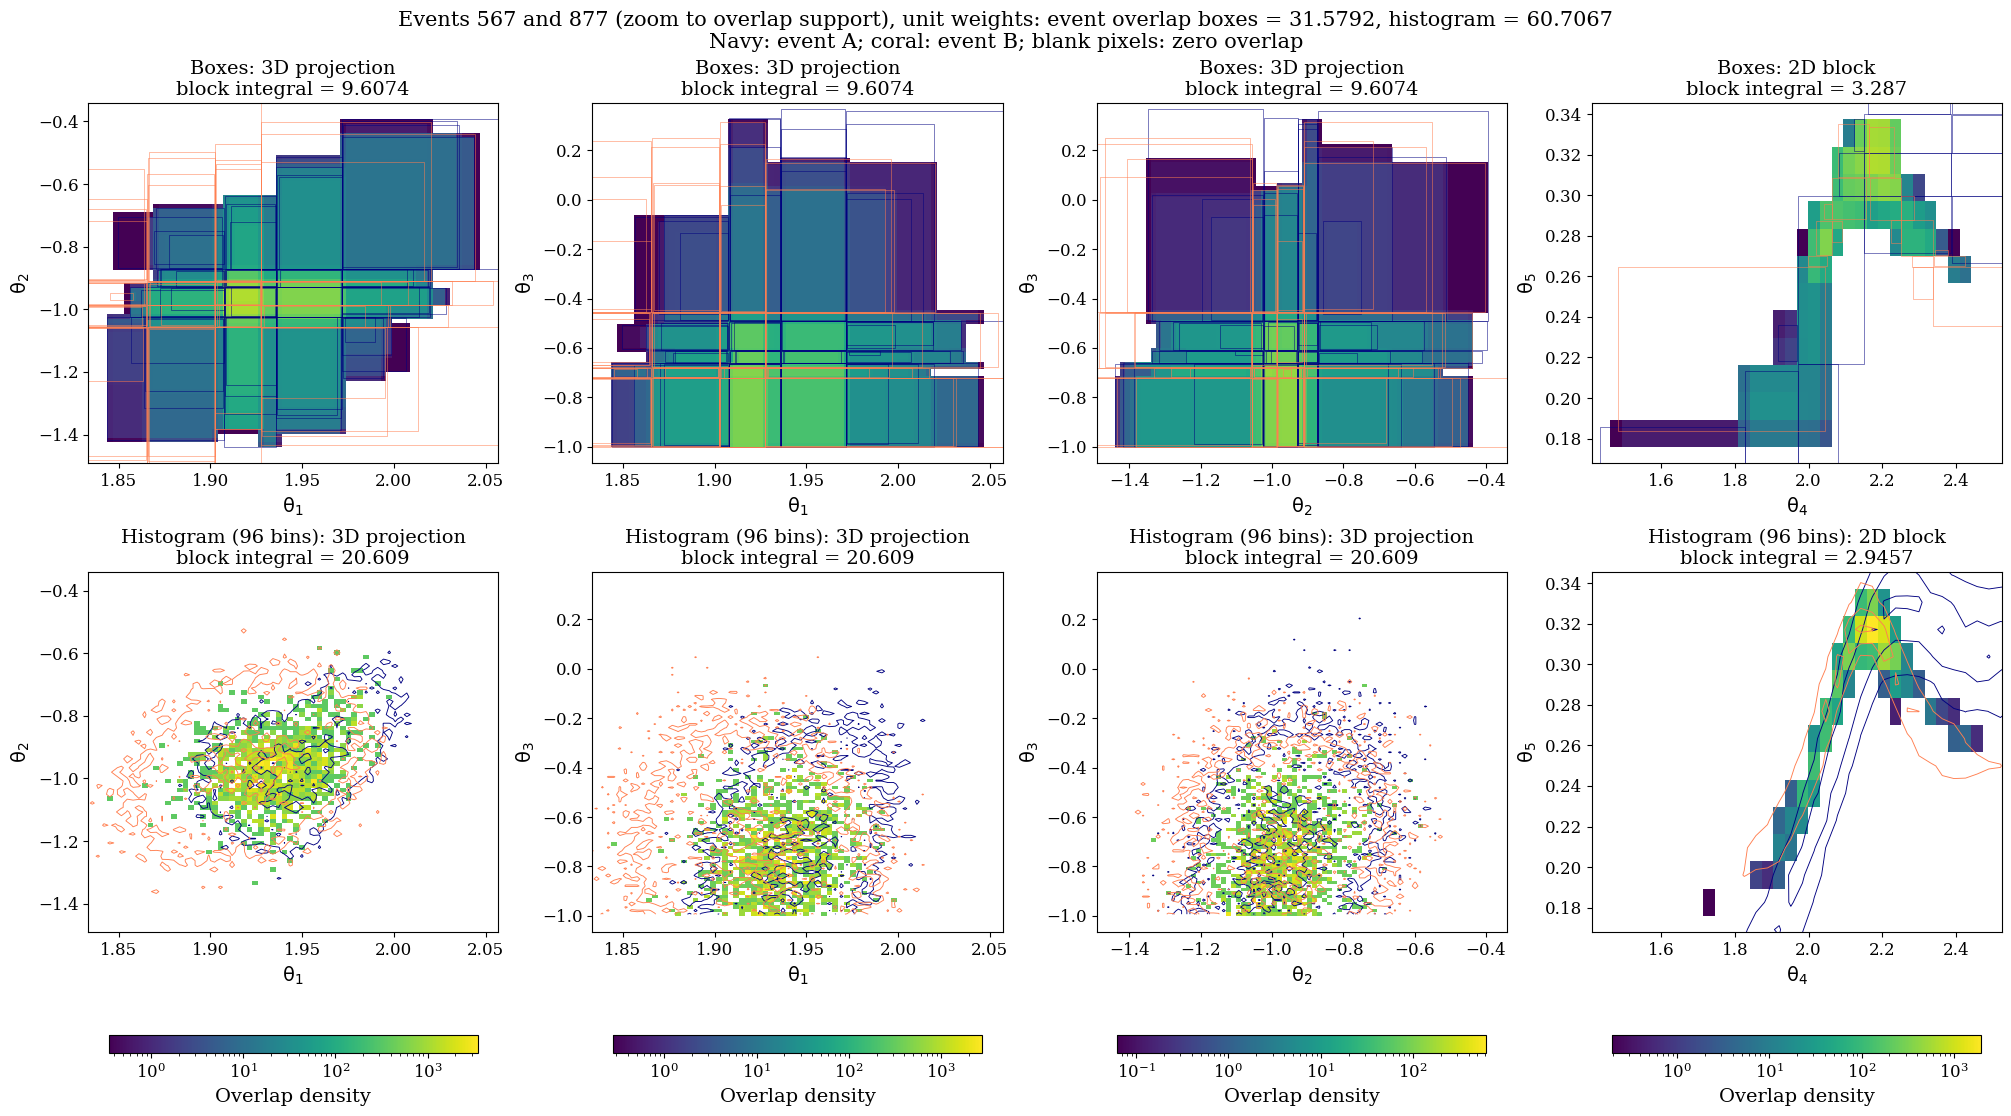

In [8]:
from plot_1v1_overlap import plot_intersection

intersection_bins = 96
intersection_folder = project_root / "validation" / "notebook_results"
intersection_folder.mkdir(exist_ok=True)
fig, intersection_maps = plot_intersection(
    samples_a, samples_b, event_a, event_b, idx1, idx2, bins=intersection_bins,
    output=intersection_folder / f"1v1_{idx1}_{idx2}.jpg")
plt.show()
fig, _ = plot_intersection(
    samples_a, samples_b, event_a, event_b, idx1, idx2, bins=intersection_bins,
    output=intersection_folder / f"1v1_{idx1}_{idx2}_zoom.jpg", zoom=True)
plt.show()


## Filtering event pairs

The BVH stores enclosing partitions from both independent blocks, with first-block coordinates first. Each subdivision level bisects every splittable group of whole boxes. Three levels give up to eight groups. All axes and cuts between sorted box centers are examined; each split minimises the sum of its children's enclosing hypervolumes. This is a local split rule, not a guarantee of globally optimal grouping. Partition bounds may overlap.

Hits from different partitions are consolidated into unique event candidates before sorted box loops check for one actual intersection in each block. No genuine box intersection is lost. Pair selection uses geometry; integral calculation still uses all density boxes. The index can instead use selected detection boxes independently of the full boxes used for the integral.


In [9]:
from bo import build_index, find_NvN, find_1vN, prepare_events, overlap_NvN_pairs

example_events = [make_event_boxes(
    np.load(project_root / "validation" / "ARAK_samples" / f"event_{i}.npy", mmap_mode="r"),
    rng=np.random.default_rng(91+i)) for i in range(100)]
full = prepare_events(example_events)
index = build_index(full, subdivisions=subdivisions)
pairs = find_NvN(index)
values = overlap_NvN_pairs(full, pairs)
print(f"100 events: {len(pairs)} intersecting pairs out of 4,950 possible pairs")
print("First pairs and their integrals:")
for pair, value in zip(pairs[:5], values[:5]):
    print(f"  {tuple(pair)}: {value:.8g}")


100 events: 194 intersecting pairs out of 4,950 possible pairs
First pairs and their integrals:
  (0, 81): 0.22384626
  (1, 3): 2.4727058e-05
  (1, 11): 6.4961593e-05
  (1, 21): 1.1298801e-05
  (2, 63): 0.00085486634



## Current dataset: full analysis

These figures and numerical results use the freshly recreated dataset and the
same default five/ten box trials as the live examples. Colors in the 100v1 and
100v5 plots indicate intersection in both full blocks, although only 2D boxes
are displayed. Histogram comparisons include every unordered pair among 1,000 events,
using 24 bins per axis.
The legend gives separate linear power-law fits for ARAK and CAMP pairs positive
in both estimates.
Each cost component uses a degree-2 log fit on 100–10,000 events; their predicted
seconds are summed for the total. Dashed curves
show the mathematical continuation up to 100 million events.
The NvN panel also shows PO2.0 (600 seconds per event plus one second per pair)
and hybrid (box total plus PO2.0 preprocessing for all events plus one second
per pair surviving box overlap). Beyond 10,000 events, hybrid holds the
measured rejection fraction at 10,000 events fixed.

![100v1](pair_finder_results/100v1.jpg)

![100v5](pair_finder_results/100v5.jpg)

![All-pair histogram comparison](pair_finder_results/histogram_comparison.jpg)

![Computational cost](pair_finder_results/scaling.jpg)

Numeric values: [timings](pair_finder_results/timings.csv),
[histogram comparisons](pair_finder_results/histogram_comparison.csv),
[100v5 integrals](pair_finder_results/100v5.csv).



## CAMP: matching connected pairs

Two independently realised PDFs share anchors from a common reference PDF.
The methods below compare matching members only and build no BVH. Detection
uses the same positive-volume intersection criterion in both blocks as indexed
finding. Integrals use the same weighted box kernel. Raw samples are not loaded.

![Example connected pair](CAMP_samples/event_0.jpg)


In [10]:

from bo import load_event_boxes, find_paired, overlap_paired
camp_folder = project_root/'validation/CAMP_results/boxes'
camp_left = [load_event_boxes(camp_folder/'event_0_0.boxes')]
camp_right = [load_event_boxes(camp_folder/'event_0_1.boxes')]
print('Matching-pair geometry:', find_paired(camp_left, camp_right))
print('Matching-pair integral:', overlap_paired(camp_left, camp_right))
print((camp_folder.parent/'comparison.json').read_text())


Matching-pair geometry: [False]
Matching-pair integral: [0.]
{
  "pairs": 1000,
  "bins": 24,
  "seed": 91,
  "ntrial": [
    5,
    10
  ],
  "n_centers": [
    4,
    8
  ],
  "positive_boxes": 718,
  "positive_histograms": 729,
  "retained_probability_mean": 0.9997672133000001,
  "checker_agrees_with_index_first_pairs": 20,
  "all_integrals_agree_with_1v1": true,
  "fits": {
    "fit_pairs": 710,
    "fits": [
      {
        "degree": 1,
        "coefficients": [
          0.6346165638050364,
          0.12024090971689251
        ],
        "rms_log10_residual": 0.3493308112819233
      }
    ],
    "x_min": 3.895803886976113e-06,
    "x_max": 217.95195834132713,
    "pairs": 1000
  },
  "histograms_agree_with_numpy_first_pairs": 20,
  "saved_box_batch_roundtrip_pairs": 1000
}




## Random trials, subdivision levels and block order

The controlled study uses 1,000 events (or the configured study count). Each
trial setting is compared at all four levels and in both orders on identical
boxes. Different trial counts can change boxes and true pair counts; changing
partitions or check order cannot change true pairs for fixed boxes.


In [11]:

import json
import os
from IPython.display import Markdown, display

study_path = project_root / "validation/pair_finder_results/rejection_study.json"
study = json.loads(study_path.read_text())
lines = ["| Trials | 2D levels | First block | Bound rejection | Exact rejection | Find (s) |",
         "| --- | ---: | --- | ---: | ---: | ---: |"]
for row in study["configurations"]:
    first = "3D" if row["block_order"][0] == 0 else "2D"
    lines.append(f"| {tuple(row['ntrial'])} | {row['subdivisions'][1]} | {first} | "
                 f"{100*row['candidate_rejection']:.4f}% | "
                 f"{100*row['pair_rejection']:.4f}% | {row['find_s']:.4f} |")
display(Markdown("\n".join(lines)))


| Trials | 2D levels | First block | Bound rejection | Exact rejection | Find (s) |
| --- | ---: | --- | ---: | ---: | ---: |
| (1, 1) | 0 | 3D | 91.0478% | 95.7632% | 0.0626 |
| (1, 1) | 0 | 2D | 91.0478% | 95.7632% | 0.0516 |
| (1, 1) | 1 | 3D | 93.2833% | 95.7632% | 0.0500 |
| (1, 1) | 1 | 2D | 93.2833% | 95.7632% | 0.0485 |
| (1, 1) | 2 | 3D | 94.2967% | 95.7632% | 0.0586 |
| (1, 1) | 2 | 2D | 94.2967% | 95.7632% | 0.0581 |
| (1, 1) | 3 | 3D | 94.7159% | 95.7632% | 0.0792 |
| (1, 1) | 3 | 2D | 94.7159% | 95.7632% | 0.0863 |
| (5, 10) | 0 | 3D | 91.0480% | 96.4120% | 0.0754 |
| (5, 10) | 0 | 2D | 91.0480% | 96.4120% | 0.0602 |
| (5, 10) | 1 | 3D | 93.4633% | 96.4120% | 0.0555 |
| (5, 10) | 1 | 2D | 93.4633% | 96.4120% | 0.0581 |
| (5, 10) | 2 | 3D | 94.6509% | 96.4120% | 0.0633 |
| (5, 10) | 2 | 2D | 94.6509% | 96.4120% | 0.0625 |
| (5, 10) | 3 | 3D | 95.2104% | 96.4120% | 0.0811 |
| (5, 10) | 3 | 2D | 95.2104% | 96.4120% | 0.0751 |


![Controlled study](pair_finder_results/rejection_study.jpg)

## One, two, four and eight enclosing groups

All four configurations share exactly the same 10,000 event boxes and a single
independent direct calculation of every pair integral. Generation and preparation
are shared costs. Enclosing groups contain whole boxes and shrink to their tight
bounds. Duplicate event candidates are consolidated before exact checks.


In [12]:

result_path = project_root / "validation/comparison_results/comparison.json"
result = json.loads(result_path.read_text())
assert result["all_pair_checks_match"]
direct = result["direct"]
display(Markdown(f"**Zero integrals: {direct['zero_pairs']:,} / "
                 f"{direct['evaluated_pairs']:,} ({100*direct['zero_fraction']:.4f}%).**"))
base = result["configurations"][0]
lines = ["| Groups (up to) | Entries | Bounds rejection | Exact rejection | Build (s) | "
         "Find (s) | Change vs one group |",
         "| ---: | ---: | ---: | ---: | ---: | ---: | ---: |"]
for row in result["configurations"]:
    change = 100*(row["find_s"]/base["find_s"]-1)
    lines.append(f"| {2**row['subdivisions'][1]} | {row['index_entries']:,} | "
                 f"{100*row['bounds_rejection']:.4f}% | "
                 f"{100*row['exact_rejection']:.4f}% | {row['index_build_s']:.4f} | "
                 f"{row['find_s']:.3f} | {change:+.2f}% |")
display(Markdown("\n".join(lines)))


**Zero integrals: 48,188,362 / 49,995,000 (96.3864%).**

| Groups (up to) | Entries | Bounds rejection | Exact rejection | Build (s) | Find (s) | Change vs one group |
| ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 1 | 10,000 | 90.9397% | 96.3864% | 0.0180 | 8.370 | +0.00% |
| 2 | 20,000 | 93.4125% | 96.3864% | 0.1979 | 7.898 | -5.64% |
| 4 | 38,790 | 94.5724% | 96.3864% | 0.3554 | 7.236 | -13.55% |
| 8 | 72,687 | 95.1383% | 96.3864% | 0.5123 | 8.833 | +5.54% |


![Partition comparison](comparison_results/comparison.jpg)

Partitioning trades tighter geometric rejection against tree traversal and
consolidation work. Exact pairs and integrals remain invariant. Single-job wall
times are subject to host/cache variation; they do not establish a universal
optimal group count. Earlier dataset numbers are superseded by these results.

[Consolidated report](report.md) · [Run instructions](../RUNNING.md)
